<!-- project-navigation -->
# 10_modeling
Role: Model experiments and analysis.

See [notebook guide](README.md) and [model comparison](../reports/model_comparison.md). Historical code and outputs are retained; run with the project root as working directory.


In [129]:
import pandas as pd

train = pd.read_csv("data/processed/train_final.csv")
test = pd.read_csv("data/processed/test_final.csv")

print("Train :", train.shape)
print("Test :", test.shape)

Train : (307511, 290)
Test : (48744, 228)


In [130]:
print(train.info())

print("\nValeurs manquantes :")
print(train.isna().sum().sum())

print("\nDoublons :")
print(train.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 290 entries, SK_ID_CURR to CC_DPD_RATIO
dtypes: float64(150), int64(140)
memory usage: 680.4 MB
None

Valeurs manquantes :
3966345

Doublons :
0


In [131]:
X = train.drop(columns=["TARGET"])
y = train["TARGET"]

print(X.shape)
print(y.shape)

(307511, 289)
(307511,)


In [132]:
X.dtypes.value_counts()

float64    150
int64      139
Name: count, dtype: int64

In [133]:
print("SK_ID_CURR" in X.columns)

True


In [134]:
X = X.drop(columns=["SK_ID_CURR"])
test = test.drop(columns=["SK_ID_CURR"])

In [135]:
print("SK_ID_CURR" in X.columns)


False


In [136]:
print(X.isna().sum().sum())
print(test.isna().sum().sum())

3966345
0


----------------------------------------------------------------------------------------------------

In [137]:
##importation
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler

from sklearn.decomposition import PCA

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay
)

import matplotlib.pyplot as plt

In [138]:
#chargement
train = pd.read_csv("data/processed/train_final.csv")
test = pd.read_csv("data/processed/test_final.csv")

print(train.shape)
print(test.shape)

(307511, 290)
(48744, 228)


In [139]:
#verification
print(train.head())

print()

print(train.info())
print(train.isna().sum().sum())
print(test.isna().sum().sum())

   SK_ID_CURR  TARGET  NAME_CONTRACT_TYPE  CODE_GENDER  FLAG_OWN_CAR  \
0      100002       1                   0            1             0   
1      100003       0                   0            0             0   
2      100004       0                   1            1             1   
3      100006       0                   0            0             0   
4      100007       0                   0            1             0   

   FLAG_OWN_REALTY  CNT_CHILDREN  AMT_INCOME_TOTAL  AMT_CREDIT  AMT_ANNUITY  \
0                1             0          202500.0    406597.5      24700.5   
1                0             0          270000.0   1293502.5      35698.5   
2                1             0           67500.0    135000.0       6750.0   
3                1             0          135000.0    312682.5      29686.5   
4                1             0          121500.0    513000.0      21865.5   

   ...  CC_AVG_BALANCE  CC_MAX_BALANCE  CC_AVG_CREDIT_LIMIT  CC_AVG_PAYMENT  \
0  ...       

In [140]:
##separation X et Y 
X = train.drop(columns=["TARGET"])

y = train["TARGET"]

print(X.shape)
print(y.shape)

(307511, 289)
(307511,)


In [141]:
X.dtypes.value_counts()

float64    150
int64      139
Name: count, dtype: int64

In [142]:
X.select_dtypes(include="object").columns.tolist()

[]

In [145]:
print(train["HOUSETYPE_MODE"].unique())

print(train["WALLSMATERIAL_MODE"].unique())
print(train["age_tranche"].unique())


[1 0 3 2]
[6 0 1 5 2 7 4 3]


KeyError: 'age_tranche'

In [ ]:
print(train["HOUSETYPE_MODE"].head())
print(test["HOUSETYPE_MODE"].head())

print(train["HOUSETYPE_MODE"].dtype)
print(test["HOUSETYPE_MODE"].dtype)

0    1
1    1
2    0
3    0
4    0
Name: HOUSETYPE_MODE, dtype: int64
0    0
1    0
2    0
3    0
4    0
Name: HOUSETYPE_MODE, dtype: int64
int64
int64


In [ ]:
print(train["WALLSMATERIAL_MODE"].head())
print(test["WALLSMATERIAL_MODE"].head())

print(train["WALLSMATERIAL_MODE"].dtype)
print(test["WALLSMATERIAL_MODE"].dtype)

print(train["age_tranche"].head())
print(test["age_tranche"].head())

print(train["age_tranche"].dtype)
print(test["age_tranche"].dtype)

0    Stone, brick
1           Block
2         Inconnu
3         Inconnu
4         Inconnu
Name: WALLSMATERIAL_MODE, dtype: str
0    0
1    0
2    0
3    0
4    0
Name: WALLSMATERIAL_MODE, dtype: int64
str
int64
0    20-30
1    40-50
2    50-60
3    50-60
4    50-60
Name: age_tranche, dtype: str
0    50-60
1    40-50
2    50-60
3    30-40
4    30-40
Name: age_tranche, dtype: str
str
str


In [ ]:
print(test["WALLSMATERIAL_MODE"].unique())

[0]


In [ ]:
print(test["WALLSMATERIAL_MODE"].value_counts())

WALLSMATERIAL_MODE
0    48744
Name: count, dtype: int64


In [ ]:
test_clean = pd.read_csv("data/processed/application_test_clean.csv")
print(test_clean["WALLSMATERIAL_MODE"].value_counts(dropna=False))

WALLSMATERIAL_MODE
Inconnu         23893
Panel           11269
Stone, brick    10434
Block            1428
Wooden            794
Mixed             353
Monolithic        289
Others            284
Name: count, dtype: int64


In [ ]:
test_clean = pd.read_csv("data/processed/application_test_clean.csv")

test["WALLSMATERIAL_MODE"] = test_clean["WALLSMATERIAL_MODE"]

In [ ]:
print(test["WALLSMATERIAL_MODE"].value_counts())

WALLSMATERIAL_MODE
Inconnu         23893
Panel           11269
Stone, brick    10434
Block            1428
Wooden            794
Mixed             353
Monolithic        289
Others            284
Name: count, dtype: int64


In [ ]:
mapping = {
    "Block": 0,
    "Inconnu": 1,
    "Mixed": 2,
    "Monolithic": 3,
    "Others": 4,
    "Panel": 5,
    "Stone, brick": 6,
    "Wooden": 7
}

train["WALLSMATERIAL_MODE"] = train["WALLSMATERIAL_MODE"].map(mapping)
test["WALLSMATERIAL_MODE"] = test["WALLSMATERIAL_MODE"].map(mapping)

In [ ]:
print(train["WALLSMATERIAL_MODE"].value_counts())
print(test["WALLSMATERIAL_MODE"].value_counts())

WALLSMATERIAL_MODE
1    156341
5     66040
6     64815
0      9253
7      5362
2      2296
3      1779
4      1625
Name: count, dtype: int64
WALLSMATERIAL_MODE
1    23893
5    11269
6    10434
0     1428
7      794
2      353
3      289
4      284
Name: count, dtype: int64


In [ ]:
train.drop(columns=["age_tranche"], inplace=True)
test.drop(columns=["age_tranche"], inplace=True)

In [ ]:
X = train.drop(columns=["TARGET", "SK_ID_CURR"])
y = train["TARGET"]

X_test = test.drop(columns=["SK_ID_CURR"])

print(X.dtypes.value_counts())

int64      138
float64     87
Name: count, dtype: int64


In [ ]:
X = train.drop(columns=["TARGET", "SK_ID_CURR"])
y = train["TARGET"]

X_test = test.drop(columns=["TARGET", "SK_ID_CURR"], errors="ignore")

print(X.shape)
print(X_test.shape)

(307511, 225)
(48744, 225)


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_test_scaled = scaler.transform(X_test)

print(X_scaled.shape)
print(X_test_scaled.shape)

(307511, 225)
(48744, 225)


In [ ]:
from sklearn.decomposition import PCA

pca = PCA()

X_pca = pca.fit_transform(X_scaled)

X_test_pca = pca.transform(X_test_scaled)

print(X_pca.shape)
print(X_test_pca.shape)

(307511, 225)
(48744, 225)


In [ ]:
print(set(X.columns) - set(X_test.columns))
print(set(X_test.columns) - set(X.columns))

set()
set()


In [ ]:
from sklearn.decomposition import PCA

pca = PCA()

X_pca = pca.fit_transform(X_scaled)

X_test_pca = pca.transform(X_test_scaled)

print(X_pca.shape)


(307511, 225)


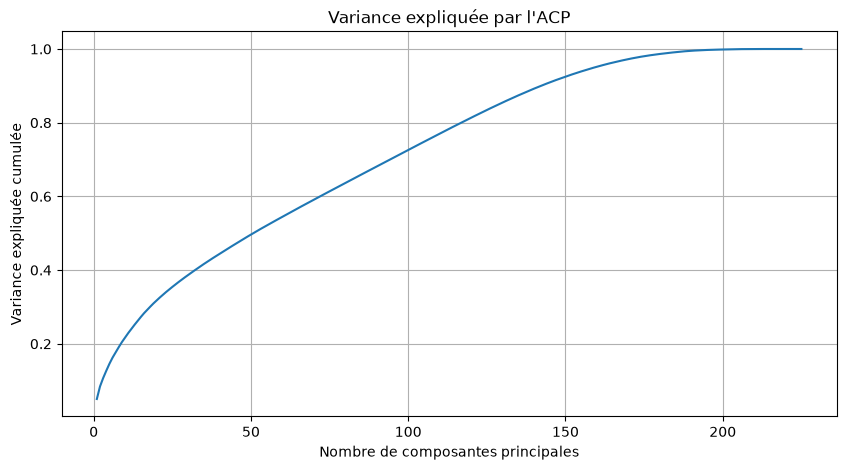

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

variance_cumulee = np.cumsum(pca.explained_variance_ratio_)

plt.figure(figsize=(10,5))
plt.plot(range(1, len(variance_cumulee)+1), variance_cumulee)
plt.xlabel("Nombre de composantes principales")
plt.ylabel("Variance expliquée cumulée")
plt.title("Variance expliquée par l'ACP")
plt.grid()
plt.show()

In [ ]:
for seuil in [0.80, 0.85, 0.90, 0.95]:
    n = np.argmax(variance_cumulee >= seuil) + 1
    print(f"{seuil*100}% de variance expliquée : {n} composantes")

80.0% de variance expliquée : 117 composantes
85.0% de variance expliquée : 129 composantes
90.0% de variance expliquée : 143 composantes
95.0% de variance expliquée : 160 composantes


In [ ]:
pca_90 = PCA(n_components=143)

X_train_pca = pca_90.fit_transform(X_scaled)

X_test_pca = pca_90.transform(X_test_scaled)

Business Understanding
        ↓
Data Understanding
        ↓
Data Preparation
        |
        |-- Nettoyage des tables
        |-- Traitement valeurs manquantes
        |-- Feature Engineering
        |-- Agrégation des tables secondaires
        |
        ↓
Fusion des tables
        |
        ↓
Encodage final
        |
        ↓
Standardisation
        |
        ↓
ACP
        |
        ↓
Modeling

In [ ]:
train_final.to_csv(
    "data/processed/train_final.csv",
    index=False
)

In [ ]:
import os

print(os.listdir("data/processed"))

['application_clean.csv', 'application_reduit.csv', 'application_test_clean.csv', 'application_test_encode.csv', 'application_test_processed.csv', 'application_train_encode.csv', 'application_train_loaded.csv', 'bureau_balance_features.csv', 'bureau_features.csv', 'credit_card_features.csv', 'installments_features.csv', 'pos_cash_features.csv', 'previous_application_features.csv', 'test_final.csv', 'train_final.csv']


In [ ]:
import pandas as pd

bureau = pd.read_csv("data/processed/bureau_features.csv")
bureau_balance = pd.read_csv("data/processed/bureau_balance_features.csv")
installments = pd.read_csv("data/processed/installments_features.csv")
pos_cash = pd.read_csv("data/processed/pos_cash_features.csv")
credit_card = pd.read_csv("data/processed/credit_card_features.csv")
previous = pd.read_csv("data/processed/previous_application_features.csv")

In [ ]:
print("bureau :", bureau.shape)
print("bureau_balance :", bureau_balance.shape)
print("installments :", installments.shape)
print("pos_cash :", pos_cash.shape)
print("credit_card :", credit_card.shape)
print("previous :", previous.shape)

bureau : (305811, 11)
bureau_balance : (305811, 8)
installments : (339587, 12)
pos_cash : (337252, 12)
credit_card : (103558, 13)
previous : (338857, 13)


In [ ]:
print("bureau :", bureau["SK_ID_CURR"].nunique(), bureau.shape[0])

print("installments :", installments["SK_ID_CURR"].nunique(), installments.shape[0])

print("previous :", previous["SK_ID_CURR"].nunique(), previous.shape[0])

print("pos_cash :", pos_cash["SK_ID_CURR"].nunique(), pos_cash.shape[0])

print("credit_card :", credit_card["SK_ID_CURR"].nunique(), credit_card.shape[0])

print("bureau_balance :", bureau_balance["SK_ID_CURR"].nunique(), bureau_balance.shape[0])

bureau : 305811 305811
installments : 339587 339587
previous : 338857 338857
pos_cash : 337252 337252
credit_card : 103558 103558
bureau_balance : 305811 305811


In [ ]:
train_final = train.copy()

tables_merge = [
    bureau,
    bureau_balance,
    installments,
    previous,
    pos_cash,
    credit_card
]


for table in tables_merge:
    
    train_final = train_final.merge(
        table,
        on="SK_ID_CURR",
        how="left"
    )

    print(train_final.shape)

(307511, 237)
(307511, 244)
(307511, 255)
(307511, 267)
(307511, 278)
(307511, 290)


In [ ]:
print(train.columns[train.columns.duplicated()])

Index([], dtype='str')


In [ ]:
for table in tables_merge:
    print("------")
    print(table.columns[table.columns.duplicated()])

------
Index([], dtype='str')
------
Index([], dtype='str')
------
Index([], dtype='str')
------
Index([], dtype='str')
------
Index([], dtype='str')
------
Index([], dtype='str')


In [ ]:
for table_name, table in zip(
    ["bureau","bureau_balance","installments","previous","pos_cash","credit_card"],
    tables_merge
):
    if "AVG_CREDIT_AMOUNT" in table.columns:
        print(table_name)

bureau
previous


In [ ]:
bureau = pd.read_csv("data/processed/bureau_features.csv")
bureau_balance = pd.read_csv("data/processed/bureau_balance_features.csv")
installments = pd.read_csv("data/processed/installments_features.csv")
previous = pd.read_csv("data/processed/previous_application_features.csv")
pos_cash = pd.read_csv("data/processed/pos_cash_features.csv")
credit_card = pd.read_csv("data/processed/credit_card_features.csv")

In [ ]:
def add_prefix(df, prefix):
    
    df = df.rename(
        columns={
            col: prefix + col
            for col in df.columns
            if col != "SK_ID_CURR"
        }
    )
    
    return df
bureau = add_prefix(bureau, "BUREAU_")

bureau_balance = add_prefix(
    bureau_balance,
    "BUREAU_BAL_"
)

installments = add_prefix(
    installments,
    "INST_"
)

previous = add_prefix(
    previous,
    "PREV_"
)

pos_cash = add_prefix(
    pos_cash,
    "POS_"
)

credit_card = add_prefix(
    credit_card,
    "CC_"
)

In [ ]:
train_final = train.copy()

tables_merge = [
    bureau,
    bureau_balance,
    installments,
    previous,
    pos_cash,
    credit_card
]


for table in tables_merge:

    train_final = train_final.merge(
        table,
        on="SK_ID_CURR",
        how="left",
        validate="one_to_one"
    )

    print(train_final.shape)

(307511, 237)
(307511, 244)
(307511, 255)
(307511, 267)
(307511, 278)
(307511, 290)


In [ ]:
test_final = test.copy()

for table in tables_merge:

    test_final = test_final.merge(
        table,
        on="SK_ID_CURR",
        how="left",
        validate="one_to_one"
    )

    print(test_final.shape)

(48744, 237)
(48744, 244)
(48744, 255)
(48744, 267)
(48744, 278)
(48744, 290)


In [ ]:
print(train_final.shape)
print(test_final.shape)

print(
    train_final["SK_ID_CURR"].nunique(),
    train_final.shape[0]
)

(307511, 290)
(48744, 290)
307511 307511


In [ ]:
X_final = train_final.drop(
    columns=["TARGET", "SK_ID_CURR"]
)

y_final = train_final["TARGET"]


X_test_final = test_final.drop(
    columns=["SK_ID_CURR"]
)
print(X_final.dtypes.value_counts())

print(
    X_final.select_dtypes(include="str").columns.tolist()
)
missing = X_final.isnull().sum()

print(
    missing[missing > 0].sort_values(ascending=False).head(20)
)
print(X_test_final.isnull().sum().sum())

float64    150
int64      138
Name: count, dtype: int64
[]
CC_MAX_DPD_DEF                        220606
CC_CREDIT_UTILIZATION_RATIO           220606
CC_DPD_RATIO                          220606
CC_MAX_BALANCE                        220606
CC_AVG_BALANCE                        220606
CC_NB_CREDIT_CARDS                    220606
CC_NB_CREDIT_CARD_RECORDS             220606
CC_MAX_DPD                            220606
CC_TOTAL_PAYMENT                      220606
CC_AVG_PAYMENT                        220606
CC_AVG_CREDIT_LIMIT                   220606
CC_NB_DELAY_MONTHS                    220606
BUREAU_NB_TOTAL_CREDITS                44020
BUREAU_NB_ACTIVE_CREDITS               44020
BUREAU_NB_OVERDUE_CREDITS              44020
BUREAU_BAL_NB_CREDITS_WITH_DELAY       44020
BUREAU_BAL_TOTAL_OK_MONTHS             44020
BUREAU_AVG_DEBT_RATIO                  44020
BUREAU_BAL_NB_CREDITS_WITH_HISTORY     44020
BUREAU_TOTAL_CREDIT                    44020
dtype: int64
524724


In [146]:
X_final = X_final.fillna(0)
X_test_final = X_test_final.fillna(0)
print(X_final.isnull().sum().sum())
print(X_test_final.isnull().sum().sum())

0
0


In [147]:
import pandas as pd
import numpy as np

# Fonction de détection IQR
def detect_outliers_iqr(df):

    outliers = {}

    for col in df.select_dtypes(include=["int64","float64"]).columns:

        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)

        IQR = Q3 - Q1

        borne_inf = Q1 - 1.5 * IQR
        borne_sup = Q3 + 1.5 * IQR

        nb_outliers = (
            (df[col] < borne_inf) |
            (df[col] > borne_sup)
        ).sum()

        if nb_outliers > 0:
            outliers[col] = nb_outliers

    return pd.Series(outliers).sort_values(
        ascending=False
    )


outliers = detect_outliers_iqr(X_final)

print(outliers.head(20))
outliers_percentage = (
    outliers / len(X_final) * 100
)

result = pd.DataFrame({
    "Nombre_outliers": outliers,
    "Pourcentage": outliers_percentage
})

print(result.head(20))
X_final[outliers.head(10).index].describe().T

REGION_RATING_CLIENT                        80527
REGION_RATING_CLIENT_W_CITY                 78027
NAME_EDUCATION_TYPE_Higher education        74863
NAME_INCOME_TYPE_Commercial associate       71617
REG_CITY_NOT_WORK_CITY                      70867
INST_PAYMENT_RATIO                          68994
PAYMENT_RATIO                               68994
ORGANIZATION_TYPE_Business Entity Type 3    67992
FLAG_WORK_PHONE                             61308
TOTAL_PAYMENT                               60687
CC_AVG_PAYMENT                              60687
CC_TOTAL_PAYMENT                            60687
AVG_PAYMENT                                 60687
CC_MAX_BALANCE                              59577
MAX_BALANCE                                 59577
CC_AVG_BALANCE                              59572
AVG_BALANCE                                 59572
CREDIT_UTILIZATION_RATIO                    59445
CC_CREDIT_UTILIZATION_RATIO                 59445
NAME_TYPE_SUITE_Unaccompanied               57693


,count,mean,std,min,25%,50%,75%,max
REGION_RATING_CLIENT,307511.0,2.052463,0.509034,1.0,2.000000,2.000000,2.000000,3.000000
REGION_RATING_CLIENT_W_CITY,307511.0,2.031521,0.502737,1.0,2.000000,2.000000,2.000000,3.000000
NAME_EDUCATION_TYPE_Higher education,307511.0,0.243448,0.429164,0.0,0.000000,0.000000,0.000000,1.000000
NAME_INCOME_TYPE_Commercial associate,307511.0,0.232892,0.422675,0.0,0.000000,0.000000,0.000000,1.000000
REG_CITY_NOT_WORK_CITY,307511.0,0.230454,0.421124,0.0,0.000000,0.000000,0.000000,1.000000
INST_PAYMENT_RATIO,307511.0,0.651414,0.164699,0.0,0.665247,0.693147,0.693147,1.869514
PAYMENT_RATIO,307511.0,0.651414,0.164699,0.0,0.665247,0.693147,0.693147,1.869514
ORGANIZATION_TYPE_Business Entity Type 3,307511.0,0.221104,0.414991,0.0,0.000000,0.000000,0.000000,1.000000
FLAG_WORK_PHONE,307511.0,0.199368,0.399526,0.0,0.000000,0.000000,0.000000,1.000000
TOTAL_PAYMENT,307511.0,2.424361,4.925080,0.0,0.000000,0.000000,0.000000,16.770948


In [ ]:
cols_financieres = [
    col for col in X_final.columns
    if any(x in col for x in [
        "AMT",
        "PAYMENT",
        "BALANCE",
        "CREDIT",
        "DEBT"
    ])
]

print(cols_financieres)
for col in cols_financieres:
    X_final[col] = np.log1p(
        X_final[col].clip(lower=0)
    )
    
    X_test_final[col] = np.log1p(
        X_test_final[col].clip(lower=0)
    )
    from sklearn.preprocessing import RobustScaler

['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'AMT_REQ_CREDIT_BUREAU_HOUR', 'AMT_REQ_CREDIT_BUREAU_DAY', 'AMT_REQ_CREDIT_BUREAU_WEEK', 'AMT_REQ_CREDIT_BUREAU_MON', 'AMT_REQ_CREDIT_BUREAU_QRT', 'AMT_REQ_CREDIT_BUREAU_YEAR', 'AMT_INCOME_TOTAL_LOG', 'NB_TOTAL_CREDITS', 'NB_ACTIVE_CREDITS', 'NB_OVERDUE_CREDITS', 'TOTAL_CREDIT', 'TOTAL_DEBT', 'TOTAL_CREDIT_LIMIT', 'AVG_CREDIT_AMOUNT_x', 'AVG_CREDIT_AGE', 'AVG_DEBT_RATIO', 'NB_CREDITS_WITH_HISTORY', 'NB_CREDITS_WITH_DELAY', 'NB_PREVIOUS_CREDITS', 'TOTAL_PAYMENT_AMOUNT', 'NB_LATE_PAYMENTS', 'AVG_PAYMENT_DELAY', 'MAX_PAYMENT_DELAY', 'AVG_PAYMENT_DIFF', 'PAYMENT_RATIO', 'LATE_PAYMENT_RATIO', 'AVG_CREDIT_AMOUNT_y', 'AVG_DOWN_PAYMENT', 'AVG_CREDIT_DURATION', 'NB_POS_CREDITS', 'NB_CREDIT_CARD_RECORDS', 'NB_CREDIT_CARDS', 'AVG_BALANCE', 'MAX_BALANCE', 'AVG_CREDIT_LIMIT', 'AVG_PAYMENT', 'TOTAL_PAYMENT', 'CREDIT_UTILIZATION_RATIO', 'BUREAU_NB_TOTAL_CREDITS', 'BUREAU_NB_ACTIVE_CREDITS', 'BUREAU_NB_OVERDUE_CREDITS', 'BUREAU_TOTAL

In [ ]:
X_final.describe().T.sort_values(
    "max",
    ascending=False
).head(20)

,count,mean,std,min,25%,50%,75%,max
INST_TOTAL_INSTALLMENT_AMOUNT,307511.0,637718.256408,869896.051461,0.0,114704.505,298091.745000,796416.907500,23274726.93
TOTAL_INSTALLMENT_AMOUNT,307511.0,637718.256408,869896.051461,0.0,114704.505,298091.745000,796416.907500,23274726.93
PREV_AVG_APPLICATION_AMOUNT,307511.0,145765.110392,153104.719432,0.0,55251.000,99848.571429,183218.625000,4050000.00
AVG_APPLICATION_AMOUNT,307511.0,145765.110392,153104.719432,0.0,55251.000,99848.571429,183218.625000,4050000.00
BUREAU_TOTAL_OVERDUE_AMOUNT,307511.0,191.107120,15271.025150,0.0,0.000,0.000000,0.000000,3756681.00
TOTAL_OVERDUE_AMOUNT,307511.0,191.107120,15271.025150,0.0,0.000,0.000000,0.000000,3756681.00
AVG_ANNUITY,307511.0,13028.060073,8817.179883,0.0,7808.913,11402.235000,16441.539375,290358.00
PREV_AVG_ANNUITY,307511.0,13028.060073,8817.179883,0.0,7808.913,11402.235000,16441.539375,290358.00
MAX_DPD_x,307511.0,14.775371,148.647441,0.0,0.000,0.000000,0.000000,4231.00
POS_MAX_DPD,307511.0,14.775371,148.647441,0.0,0.000,0.000000,0.000000,4231.00


In [ ]:
cols_log = [
    "INST_TOTAL_INSTALLMENT_AMOUNT",
    "TOTAL_INSTALLMENT_AMOUNT",
    "PREV_AVG_APPLICATION_AMOUNT",
    "AVG_APPLICATION_AMOUNT",
    "BUREAU_TOTAL_OVERDUE_AMOUNT",
    "TOTAL_OVERDUE_AMOUNT",
    "AVG_ANNUITY",
    "PREV_AVG_ANNUITY",
    "MAX_DPD_x",
    "POS_MAX_DPD",
    "MAX_DPD_DEF_x",
    "POS_MAX_DPD_DEF",
    "CC_MAX_DPD",
    "MAX_DPD_y",
    "MAX_DPD_DEF_y",
    "CC_MAX_DPD_DEF",
    "BUREAU_BAL_TOTAL_OK_MONTHS",
    "TOTAL_OK_MONTHS",
    "BUREAU_BAL_TOTAL_DELAY_MONTHS",
    "TOTAL_DELAY_MONTHS"
]
for col in cols_log:
    
    if col in X_final.columns:
        
        X_final[col] = np.log1p(
            X_final[col]
        )

        X_test_final[col] = np.log1p(
            X_test_final[col]
        )
       

In [ ]:
X_final[cols_log].describe().T

,count,mean,std,min,25%,50%,75%,max
INST_TOTAL_INSTALLMENT_AMOUNT,307511.0,1.218234,0.285277,0.0,1.263467,1.283832,1.302965,1.357974
TOTAL_INSTALLMENT_AMOUNT,307511.0,1.218234,0.285277,0.0,1.263467,1.283832,1.302965,1.357974
PREV_AVG_APPLICATION_AMOUNT,307511.0,1.189856,0.292584,0.0,1.246512,1.260346,1.273691,1.331281
AVG_APPLICATION_AMOUNT,307511.0,1.189856,0.292584,0.0,1.246512,1.260346,1.273691,1.331281
BUREAU_TOTAL_OVERDUE_AMOUNT,307511.0,0.011051,0.106903,0.0,0.000000,0.000000,0.000000,1.330052
TOTAL_OVERDUE_AMOUNT,307511.0,0.011051,0.106903,0.0,0.000000,0.000000,0.000000,1.330052
AVG_ANNUITY,307511.0,1.140779,0.271701,0.0,1.193587,1.204826,1.215196,1.283296
PREV_AVG_ANNUITY,307511.0,1.140779,0.271701,0.0,1.193587,1.204826,1.215196,1.283296
MAX_DPD_x,307511.0,0.135727,0.300741,0.0,0.000000,0.000000,0.000000,1.174159
POS_MAX_DPD,307511.0,0.135727,0.300741,0.0,0.000000,0.000000,0.000000,1.174159


In [ ]:
duplicates = []

cols = X_final.columns

for i in range(len(cols)):
    for j in range(i+1, len(cols)):
        if X_final[cols[i]].equals(X_final[cols[j]]):
            duplicates.append((cols[i], cols[j]))

print(len(duplicates))
print(duplicates[:20])

49
[('NB_TOTAL_CREDITS', 'NB_CREDITS_WITH_HISTORY'), ('NB_TOTAL_CREDITS', 'BUREAU_NB_TOTAL_CREDITS'), ('NB_TOTAL_CREDITS', 'BUREAU_BAL_NB_CREDITS_WITH_HISTORY'), ('NB_ACTIVE_CREDITS', 'BUREAU_NB_ACTIVE_CREDITS'), ('NB_OVERDUE_CREDITS', 'BUREAU_NB_OVERDUE_CREDITS'), ('TOTAL_CREDIT', 'BUREAU_TOTAL_CREDIT'), ('TOTAL_DEBT', 'BUREAU_TOTAL_DEBT'), ('TOTAL_CREDIT_LIMIT', 'BUREAU_TOTAL_CREDIT_LIMIT'), ('TOTAL_OVERDUE_AMOUNT', 'BUREAU_TOTAL_OVERDUE_AMOUNT'), ('NB_CREDITS_WITH_HISTORY', 'BUREAU_NB_TOTAL_CREDITS'), ('NB_CREDITS_WITH_HISTORY', 'BUREAU_BAL_NB_CREDITS_WITH_HISTORY'), ('MAX_DELAY', 'BUREAU_BAL_MAX_DELAY'), ('TOTAL_DELAY_MONTHS', 'BUREAU_BAL_TOTAL_DELAY_MONTHS'), ('AVG_DELAY_RATIO', 'BUREAU_BAL_AVG_DELAY_RATIO'), ('NB_CREDITS_WITH_DELAY', 'BUREAU_BAL_NB_CREDITS_WITH_DELAY'), ('TOTAL_OK_MONTHS', 'BUREAU_BAL_TOTAL_OK_MONTHS'), ('NB_INSTALLMENTS', 'INST_NB_INSTALLMENTS'), ('NB_PREVIOUS_CREDITS', 'INST_NB_PREVIOUS_CREDITS'), ('TOTAL_INSTALLMENT_AMOUNT', 'INST_TOTAL_INSTALLMENT_AMOUNT'), (

In [ ]:
# Colonnes à supprimer (on garde la première occurrence)
cols_to_drop = []

for col1, col2 in duplicates:
    if col2 not in cols_to_drop:
        cols_to_drop.append(col2)

print("Nombre de colonnes supprimées :", len(cols_to_drop))

X_final_clean = X_final.drop(
    columns=cols_to_drop
)

print("Avant :", X_final.shape)
print("Après :", X_final_clean.shape)

Nombre de colonnes supprimées : 46
Avant : (307511, 288)
Après : (307511, 242)


In [ ]:
duplicates_after = []

cols = X_final_clean.columns

for i in range(len(cols)):
    for j in range(i+1, len(cols)):
        if X_final_clean[cols[i]].equals(X_final_clean[cols[j]]):
            duplicates_after.append(
                (cols[i], cols[j])
            )

print(len(duplicates_after))

0


In [ ]:
X_final_clean.dtypes.value_counts()

int64      138
float64    104
Name: count, dtype: int64

----------------------ACP------------------------------

In [ ]:
print(X_train.isnull().sum().sum())
print(X_valid.isnull().sum().sum())

3171654
794691


In [ ]:
nan_cols = X_train.columns[X_train.isnull().any()]

print(len(nan_cols))
print(X_train[nan_cols].isnull().sum().sort_values(ascending=False))

63
CC_MAX_DPD_DEF                 176325
CC_CREDIT_UTILIZATION_RATIO    176325
CC_DPD_RATIO                   176325
CC_MAX_BALANCE                 176325
CC_AVG_BALANCE                 176325
                                ...  
INST_PAYMENT_RATIO              12686
INST_MAX_PAYMENT_DELAY          12686
INST_TOTAL_PAYMENT_AMOUNT       12686
INST_NB_LATE_PAYMENTS           12686
INST_AVG_PAYMENT_DELAY          12686
Length: 63, dtype: int64


In [ ]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")

X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_valid_imputed = pd.DataFrame(
    imputer.transform(X_valid),
    columns=X_valid.columns,
    index=X_valid.index
)

print("NaN train :", X_train_imputed.isnull().sum().sum())
print("NaN valid :", X_valid_imputed.isnull().sum().sum())

NaN train : 0
NaN valid : 0


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_valid_scaled = scaler.transform(X_valid_imputed)

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=133)

X_train_pca = pca.fit_transform(X_train_scaled)
X_valid_pca = pca.transform(X_valid_scaled)

print(X_train_pca.shape)
print(X_valid_pca.shape)

(246008, 133)
(61503, 133)


# Synthèse de la phase Data Preparation et réduction dimensionnelle (ACP)

## 1. Préparation des différentes sources de données

Dans le cadre du projet de prédiction du risque de crédit (*Credit Risk Prediction*), les données provenant de plusieurs tables du dataset **Home Credit Default Risk** ont été préparées séparément avant leur intégration finale.

Les tables utilisées sont :

- **Application_train / Application_test** : informations principales sur les demandeurs de crédit (profil client, revenu, situation professionnelle, caractéristiques du prêt).
- **Bureau** : historique des crédits obtenus auprès d'autres institutions financières.
- **Bureau_balance** : historique mensuel des crédits présents dans la table bureau.
- **Previous_application** : informations sur les anciennes demandes de crédit.
- **POS_CASH_balance** : historique des crédits POS et cash.
- **Installments_payments** : historique des paiements effectués.
- **Credit_card_balance** : historique des cartes de crédit.

Chaque table a subi une phase de préparation comprenant :

- Analyse des types de variables.
- Suppression des variables fortement incomplètes ou non pertinentes.
- Traitement des valeurs manquantes.
- Détection et correction des valeurs aberrantes connues.
- Création de nouvelles variables explicatives (*Feature Engineering*).

---

# 2. Traitement des valeurs manquantes

Une analyse complète des valeurs manquantes a été réalisée afin d'adapter la stratégie de traitement selon la nature des variables.

Les méthodes appliquées sont :

- **Variables numériques :**
    - Remplacement par la médiane lorsque la variable représente une mesure quantitative.
    - Remplacement par 0 lorsque l'absence de valeur représente une absence d'événement (exemple : absence de crédit ou absence de retard).

- **Variables catégorielles :**
    - Remplacement par la modalité la plus fréquente (*mode*).
    - Création d'une catégorie "Unknown" lorsque l'information était réellement inconnue.

Cette étape permet d'obtenir des jeux de données complets nécessaires aux algorithmes de Machine Learning.

Après traitement :

- Nombre de valeurs manquantes finales : **0**
- Nombre de doublons : **0**

---

# 3. Feature Engineering

Afin d'améliorer la capacité prédictive des modèles, plusieurs variables dérivées ont été créées :

### Variables temporelles

Transformation de :

- `DAYS_BIRTH` en âge réel en années :

    Age = -DAYS_BIRTH / 365

- Création des tranches d'âge afin de capturer des comportements différents selon les profils clients.


### Traitement des anomalies

La variable :

`DAYS_EMPLOYED = 365243`

correspondait à une valeur aberrante représentant une anomalie.

Une variable indicatrice a été créée :

`DAYS_EMPLOYED_ANOM`

puis la valeur aberrante a été remplacée par une valeur représentative.


### Transformation des variables fortement asymétriques

La variable :

`AMT_INCOME_TOTAL`

présentait une forte asymétrie avec quelques valeurs extrêmes.

Une transformation logarithmique a été appliquée :

`AMT_INCOME_TOTAL_LOG = log(1 + AMT_INCOME_TOTAL)`

Cette transformation réduit l'effet des valeurs extrêmes et améliore la stabilité des modèles.

---

# 4. Encodage des variables catégorielles

Les variables catégorielles ont été transformées en variables numériques afin d'être utilisées par les modèles de Machine Learning.

Deux méthodes ont été utilisées :

### Label Encoding

Appliqué aux variables binaires :

- NAME_CONTRACT_TYPE
- CODE_GENDER
- FLAG_OWN_CAR
- FLAG_OWN_REALTY


### One Hot Encoding

Appliqué aux variables comportant plusieurs catégories :

- NAME_INCOME_TYPE
- NAME_EDUCATION_TYPE
- NAME_FAMILY_STATUS
- NAME_HOUSING_TYPE
- OCCUPATION_TYPE
- ORGANIZATION_TYPE
- WEEKDAY_APPR_PROCESS_START
- WALLSMATERIAL_MODE
- HOUSETYPE_MODE

L'option `drop_first=True` a été utilisée afin d'éviter le problème de multicolinéarité.

---

# 5. Fusion des différentes tables

Après préparation individuelle des tables, une fusion finale a été réalisée autour de la clé commune :

`SK_ID_CURR`

La jointure utilisée est une jointure gauche (*left join*) afin de conserver tous les clients présents dans la table principale `application_train`.

La fusion permet d'obtenir un dataset global contenant :

- Les caractéristiques personnelles du client.
- Son historique bancaire.
- Ses comportements de paiement.
- Ses crédits précédents.
- Ses informations financières.

Résultat final :

- Train final :
    - Dimensions : **(307511, 290)**

- Test final :
    - Dimensions : **(48744, 290)**


Les datasets finaux ont été sauvegardés :

`train_final.csv`

`test_final.csv`

dans le dossier :

`data/processed/`

---

# 6. Contrôle qualité après fusion

Plusieurs vérifications ont été réalisées :

- Vérification des dimensions après chaque fusion.
- Vérification des types des variables.
- Vérification des valeurs manquantes.
- Recherche des doublons.
- Vérification de la cohérence entre train et test.

Résultats :

- Valeurs manquantes : 0
- Doublons : 0
- Variables numériques prêtes pour le modèle.

---

# 7. Détection des valeurs aberrantes

Une analyse statistique a été réalisée avec les indicateurs :

- Minimum
- Maximum
- Moyenne
- Écart-type
- Quartiles

Certaines variables présentaient des valeurs extrêmes :

Exemples :

- TOTAL_OVERDUE_AMOUNT
- MAX_DPD
- TOTAL_DELAY_MONTHS
- INST_TOTAL_INSTALLMENT_AMOUNT

Cependant, ces valeurs correspondent à des comportements financiers réels :

- Retards importants de paiement.
- Historique de défaut.
- Montants élevés de crédits.

Elles n'ont donc pas été supprimées car elles représentent une information importante pour la prédiction du risque.

---

# 8. Suppression des variables dupliquées

Après fusion, certaines variables étaient identiques provenant de différentes sources.

Une analyse de duplication colonne par colonne a permis d'identifier :

- 49 colonnes totalement identiques.

Ces variables ont été supprimées afin :

- De réduire la redondance.
- D'éviter la multicolinéarité.
- D'améliorer l'efficacité des modèles.

Après suppression :

Nombre final de variables utilisées :

- Variables numériques : 242 environ.

---

# 9. Analyse en Composantes Principales (ACP)

## Pourquoi appliquer l'ACP dans la phase Modeling ?

L'ACP a été réalisée dans la phase **Modeling** et non dans la phase Data Preparation car elle constitue une méthode de réduction de dimension utilisée pour préparer les données avant l'apprentissage automatique.

Objectifs :

- Réduire le nombre de variables.
- Supprimer la redondance entre variables corrélées.
- Construire de nouvelles variables synthétiques appelées composantes principales.
- Réduire le temps d'entraînement des modèles.
- Améliorer la stabilité des algorithmes sensibles à la dimension.

Avant l'ACP :

Les variables numériques ont été standardisées avec :

`StandardScaler`

afin que chaque variable ait :

- Moyenne = 0
- Écart-type = 1

Cette étape est obligatoire car l'ACP dépend de la variance des variables.

---

# 10. Résultats de l'ACP

L'analyse de la variance expliquée a montré :

| Variance expliquée | Nombre de composantes |
|--------------------|-----------------------|
| 80% | 107 composantes |
| 85% | 120 composantes |
| 90% | 133 composantes |
| 95% | 150 composantes |


Le choix retenu est :
### Réduction dimensionnelle par Analyse en Composantes Principales (ACP)

Une Analyse en Composantes Principales (ACP) a été appliquée après les étapes de nettoyage, d'encodage, d'imputation des valeurs manquantes et de standardisation des variables numériques.

Le nombre de composantes principales a été choisi afin de conserver **90% de la variance totale expliquée**. Cette étape permet de réduire la dimensionnalité des données tout en conservant l'essentiel de l'information nécessaire à la modélisation.

Le nombre optimal obtenu est de **133 composantes principales**.

Dimensions après transformation :

**Jeu d'entraînement :**

(246008, 133)

**Jeu de validation :**

(61503, 133)

Ainsi, l'ACP permet de réduire l'espace initial contenant plusieurs centaines de variables à un espace de **133 dimensions**, tout en conservant 90% de l'information présente dans les données.

Cette réduction permet :
- de diminuer la complexité des modèles,
- de limiter la multicolinéarité entre variables fortement corrélées,
- d'améliorer l'efficacité des algorithmes de Machine Learning.
# Conclusion

La phase Data Preparation est maintenant terminée.

Les données sont :

- Nettoyées.
- Complètes.
- Fusionnées.
- Encodées.
- Réduites dimensionnellement.

Le dataset final est prêt pour la phase suivante :

## Modeling

avec l'entraînement et l'évaluation des modèles de Machine Learning pour prédire le risque de défaut (`TARGET`).

----------------MODELING---------------------------------


In [161]:
from sklearn.linear_model import LogisticRegression

model_lr_no_pca = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)
model_lr_no_pca.fit(
    X_train_scaled,
    y_train
)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default 

In [ ]:
y_pred_no_pca = model_lr_no_pca.predict(X_valid_scaled)

In [ ]:
print(y_pred_no_pca.shape)

(61503,)


In [ ]:
print(y_pred_no_pca[:20])

[0 0 1 0 1 1 0 0 1 1 0 0 0 1 1 0 1 0 0 0]


In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_valid, y_pred_no_pca)

print(cm)

[[40123 16415]
 [ 1498  3467]]


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_valid, y_pred_no_pca))

              precision    recall  f1-score   support

           0       0.96      0.71      0.82     56538
           1       0.17      0.70      0.28      4965

    accuracy                           0.71     61503
   macro avg       0.57      0.70      0.55     61503
weighted avg       0.90      0.71      0.77     61503



In [ ]:
from sklearn.metrics import roc_auc_score

y_prob_no_pca = model_lr_no_pca.predict_proba(X_valid_scaled)[:,1]

auc_no_pca = roc_auc_score(
    y_valid,
    y_prob_no_pca
)

print("ROC-AUC sans ACP :", auc_no_pca)

ROC-AUC sans ACP : 0.7704765684956535


# Modèle 1 : Logistic Regression sans ACP (modèle de référence)

## 1. Objectif du modèle

L'objectif est de construire un modèle de classification binaire permettant de prédire le risque de défaut de paiement des clients.

Dans le contexte du projet Home Credit Default Risk :

- La variable cible est `TARGET`.
- `TARGET = 0` représente un client qui rembourse son crédit.
- `TARGET = 1` représente un client en situation de défaut.

Le problème est donc une classification binaire :
- Classe 0 : client non risqué
- Classe 1 : client risqué


---

## 2. Préparation des données utilisées

Avant l'entraînement du modèle, plusieurs étapes de préparation ont été réalisées :

- Traitement des valeurs manquantes afin d'obtenir un jeu de données complet.
- Encodage des variables catégorielles pour transformer les informations qualitatives en valeurs numériques exploitables par le modèle.
- Standardisation des variables numériques afin de mettre les différentes variables sur une échelle comparable.

La standardisation est importante pour la Logistic Regression car le modèle est basé sur une combinaison linéaire des variables.


Les données utilisées pour ce premier modèle sont les variables originales standardisées :

X_train_scaled :
- Variables explicatives des clients après préparation et standardisation.

y_train :
- Variable cible contenant l'information sur le défaut de paiement.


---

## 3. Création du modèle

Le modèle choisi est une Logistic Regression.

La Logistic Regression est un algorithme adapté aux problèmes de classification binaire.
Elle permet d'estimer la probabilité qu'un client appartienne à une classe donnée.

Dans notre cas, le modèle estime :

P(TARGET = 1)

c'est-à-dire la probabilité qu'un client présente un risque de défaut.


Le paramètre utilisé :

`class_weight="balanced"`

permet de prendre en compte le déséquilibre des classes.

En effet, le dataset contient beaucoup plus de clients sans défaut que de clients en défaut.

Sans équilibrage, le modèle pourrait privilégier la classe majoritaire (0) et mal détecter les clients risqués.


---

## 4. Entraînement du modèle

Le modèle est entraîné avec :

model_lr_no_pca.fit(X_train_scaled, y_train)

Pendant cette étape, l'algorithme apprend la relation entre :

Les caractéristiques des clients :
- revenus
- âge
- informations financières
- historiques
- variables externes

et la variable cible :

TARGET (0 ou 1)


Le modèle apprend donc quels profils de clients sont associés à un risque plus élevé de défaut.


---

## 5. Prédiction sur les données de validation

Après l'apprentissage, le modèle est testé sur un ensemble de validation jamais utilisé pendant l'entraînement.

La prédiction est réalisée avec :

y_pred_no_pca = model_lr_no_pca.predict(X_valid_scaled)


Le modèle fournit pour chaque client une classe :

- 0 : client prédit sans défaut
- 1 : client prédit en défaut


Exemple :

[0 0 1 0 1 ...]

signifie que le modèle prédit :
- client 1 : pas de défaut
- client 2 : pas de défaut
- client 3 : défaut
etc.


---

# 6. Evaluation du modèle

## 6.1 Matrice de confusion

La matrice obtenue est :

[[40123 16415]
 [ 1498  3467]]


Elle permet de comparer les valeurs réelles avec les prédictions.


Résultats :

### True Negative (TN) = 40123

Clients réellement sans défaut et correctement classés par le modèle.


### True Positive (TP) = 3467

Clients réellement en défaut et correctement détectés.

C'est un résultat important car il correspond aux clients risqués identifiés.


### False Positive (FP) = 16415

Clients sans défaut mais classés comme risqués.

Cela représente des clients potentiellement refusés alors qu'ils auraient pu rembourser.


### False Negative (FN) = 1498

Clients en défaut mais classés comme fiables.

C'est l'erreur la plus critique dans un contexte bancaire car elle représente des clients risqués acceptés.


---

# 6.2 Classification Report


Résultats obtenus :

Classe 0 :

Precision = 0.96
Recall = 0.71
F1-score = 0.82


Classe 1 :

Precision = 0.17
Recall = 0.70
F1-score = 0.28


## Analyse de la classe défaut (classe 1)

La métrique la plus importante est le recall.

Recall classe 1 = 0.70

Cela signifie que :

70% des clients qui présentent réellement un défaut sont détectés par le modèle.


Cependant :

Precision classe 1 = 0.17

Cela signifie que parmi les clients prédits comme risqués, seulement 17% sont réellement en défaut.

Le modèle génère donc un nombre important de faux positifs.


Ce comportement est attendu car le paramètre class_weight="balanced" favorise la détection de la classe minoritaire.


---

# 6.3 Probabilité de défaut et ROC-AUC

Au lieu de prédire uniquement une classe 0 ou 1, la Logistic Regression permet également d'obtenir une probabilité de défaut.

Cette probabilité est obtenue avec :

predict_proba()


Elle représente le niveau de risque individuel du client.

Exemple :

Client A : probabilité défaut = 0.05 → faible risque

Client B : probabilité défaut = 0.80 → risque élevé


La métrique ROC-AUC permet d'évaluer la capacité globale du modèle à distinguer les clients fiables des clients risqués.


Résultat obtenu :

ROC-AUC = 0.7705


Interprétation :

Le modèle possède une capacité correcte de discrimination entre les deux classes.

Un score de 0.77 indique une performance acceptable pour un premier modèle de scoring crédit.


---

# 7. Conclusion du modèle sans ACP

Le premier modèle Logistic Regression sans ACP constitue le modèle de référence.

Résultats :

- ROC-AUC : 0.7705
- Recall défaut : 70%
- Precision défaut : 17%


Le modèle détecte correctement une grande partie des clients risqués, ce qui est important pour limiter les défauts de crédit.

Cependant, il génère beaucoup de faux positifs, ce qui indique un compromis entre la détection du risque et l'acceptation des bons clients.


Ce modèle servira de référence pour comparer l'impact de l'ACP sur :
- la performance prédictive,
- la réduction de dimension,
- et l'équilibre entre performance et explicabilité.

1) Analyse de la matrice de confusion

La matrice obtenue est :

                 Prédiction
              0          1

Réel 0     40123      16415

Réel 1      1498       3467

Cette matrice permet d'évaluer le comportement du modèle en comparant :

la classe réelle (y_valid)
la classe prédite (y_pred_no_pca)
A) Détection des clients sans défaut (classe 0)
True Negative (TN) = 40 123

Cela représente les clients :

réellement capables de rembourser leur crédit (TARGET=0)
correctement identifiés comme fiables par le modèle.

Interprétation métier :

Le modèle réussit à reconnaître une grande partie des clients qui ne présentent pas de risque de défaut.

Ces clients peuvent être considérés comme des dossiers moins risqués.

False Positive (FP) = 16 415

Cela représente les clients :

réellement fiables (TARGET=0)
mais classés par le modèle comme risqués (prediction=1).

Interprétation métier :

Le modèle est relativement prudent : il signale comme risqués plusieurs clients qui auraient probablement remboursé leur crédit.

Conséquence pour la banque :

augmentation des analyses manuelles
risque de refuser certains bons clients
perte potentielle d'opportunités commerciales

Ce nombre élevé explique pourquoi la precision de la classe 1 est faible.

B) Détection des clients en défaut (classe 1)
True Positive (TP) = 3 467

Ce sont les clients :

réellement en défaut (TARGET=1)
correctement détectés par le modèle.

Interprétation métier :

Le modèle réussit à identifier 3 467 clients présentant un risque réel de défaut.

Ces clients sont les plus importants à détecter dans un système de scoring crédit.

False Negative (FN) = 1 498

Ce sont les clients :

réellement en défaut
mais classés comme clients fiables.

Interprétation métier :

Le modèle laisse passer 1 498 clients risqués.

C'est l'erreur la plus coûteuse pour une banque car elle peut entraîner :

des crédits accordés à des clients qui ne rembourseront pas
une augmentation du taux de défaut
des pertes financières

Cependant, ce nombre reste inférieur aux vrais défauts détectés :

Défauts détectés : 3467
Défauts manqués : 1498
2) Analyse de la classe défaut (classe 1)

La classe 1 est la classe la plus importante dans ton projet.

Résultats :

Precision = 0.17
Recall    = 0.70
F1-score  = 0.28
A) Recall = 70% ⭐

Formule :

Recall=
TP+FN
TP
	​


Dans ton cas :

Recall=
3467+1498
3467
	​


≈ 0.70

Interprétation :

Parmi tous les clients qui ont réellement fait défaut, le modèle en détecte environ 70%.

Exemple concret :

Sur 100 clients qui vont réellement être en défaut :

environ 70 seront détectés comme risqués
environ 30 passeront comme clients fiables

C'est un résultat intéressant pour un premier modèle de risque crédit.

Pourquoi ?

Parce qu'en banque, il est généralement préférable de détecter un maximum de clients risqués.

B) Precision = 17% ⚠️

Formule :

Precision=
TP+FP
TP
	​


Dans ton cas :

Precision=
3467+16415
3467
	​


≈ 0.17

Interprétation :

Parmi les clients que le modèle classe comme risqués :

seulement 17% sont réellement en défaut
83% sont de faux signaux

Exemple :

Le modèle sélectionne 100 clients comme risqués :

17 feront réellement défaut
83 auraient probablement remboursé

Pourquoi cette valeur est faible ?

Principalement à cause :

Du déséquilibre du dataset :
Classe 0 ≈ 92%
Classe 1 ≈ 8%
Du choix :
class_weight="balanced"

Ce paramètre force le modèle à mieux détecter la classe minoritaire.

Conséquence :

→ il devient plus sensible aux défauts
→ mais il produit plus de fausses alertes.

C) F1-score = 28%

Le F1-score combine :

precision
recall

Formule :

F1=2×
Precision+Recall
Precision×Recall
	​


Résultat :

F1 classe 1 = 0.28

Interprétation :

Le modèle a un bon niveau de détection, mais manque de précision.

Il privilégie :

détecter un maximum de clients risqués

au détriment de :

éviter les fausses alertes.

3) Analyse de l'Accuracy = 71%

Résultat :

Accuracy = 0.71

Cela signifie :

71% des prédictions globales sont correctes.

Mais cette métrique est moins pertinente ici.

Pourquoi ?

Parce que les classes sont déséquilibrées :

Clients sans défaut : 56538
Clients en défaut    : 4965

Un modèle qui prédirait toujours 0 pourrait déjà obtenir une grande accuracy.

Donc dans un contexte crédit, on privilégie :

Recall classe 1
ROC-AUC
F1-score
matrice de confusion
4) Analyse du ROC-AUC = 0.7705 ⭐

Résultat :

ROC-AUC = 0.7705

Le ROC-AUC mesure la capacité du modèle à séparer :

Clients fiables
        VS
Clients risqués

Interprétation :

0.5 → hasard
0.7-0.8 → modèle acceptable
0.8-0.9 → bon modèle

Donc :

0.7705

signifie :

Le modèle possède une capacité correcte à distinguer les clients présentant un risque de défaut des clients fiables.

Ce résultat est satisfaisant pour un premier modèle de référence.

5) Analyse globale du comportement du modèle

Le modèle présente un comportement :

Avantages :

✅ Bonne détection des défauts :

Recall classe 1 = 70%

✅ ROC-AUC correcte :

0.7705

✅ Adapté comme modèle de référence.

Limites :

⚠️ Beaucoup de faux positifs :

FP = 16415

⚠️ Faible précision :

Precision classe 1 = 17%

Le modèle est donc trop prudent.

-------------------- AVEC ACP---------------------------------


In [ ]:
from sklearn.linear_model import LogisticRegression

model_lr_pca = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

In [ ]:
model_lr_pca.fit(
    X_train_pca,
    y_train
)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default 

In [ ]:
y_pred_pca = model_lr_pca.predict(X_valid_pca)

In [ ]:
print(y_pred_pca.shape)

print(y_pred_pca[:20])

(61503,)
[0 1 0 1 1 1 0 0 1 1 0 1 0 1 1 0 1 0 1 0]


In [ ]:
model_lr_pca = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

In [ ]:
model_lr_pca.fit(
    X_train_pca,
    y_train
)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default 

In [ ]:
y_pred_pca = model_lr_pca.predict(X_valid_pca)

print(y_pred_pca.shape)
print(y_pred_pca[:20])

(61503,)
[0 1 0 1 1 1 0 0 1 1 0 1 0 1 1 0 1 0 1 0]


In [ ]:
from sklearn.metrics import confusion_matrix

cm_pca = confusion_matrix(
    y_valid,
    y_pred_pca
)

print(cm_pca)

[[39070 17468]
 [ 1559  3406]]


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_valid, y_pred_pca))

              precision    recall  f1-score   support

           0       0.96      0.69      0.80     56538
           1       0.16      0.69      0.26      4965

    accuracy                           0.69     61503
   macro avg       0.56      0.69      0.53     61503
weighted avg       0.90      0.69      0.76     61503



In [ ]:
from sklearn.metrics import roc_auc_score

y_prob_pca = model_lr_pca.predict_proba(X_valid_pca)[:,1]

auc_pca = roc_auc_score(
    y_valid,
    y_prob_pca
)

print("ROC-AUC avec ACP :", auc_pca)

ROC-AUC avec ACP : 0.7520843328037141


# Interprétation détaillée des résultats — Logistic Regression avec ACP

## 1. Présentation du modèle

Dans cette deuxième approche, une Analyse en Composantes Principales (ACP) a été appliquée avant l'entraînement du modèle de classification.

L'objectif de cette étape est de :

- réduire la dimension des données ;
- supprimer la redondance entre variables corrélées ;
- conserver la majorité de l'information contenue dans les variables initiales.

Contrairement au premier modèle qui utilise directement les variables originales standardisées, ce modèle utilise comme variables d'entrée les composantes principales générées par l'ACP.

Le pipeline utilisé est donc :

Données préparées  
↓  
Encodage des variables catégorielles  
↓  
Standardisation des variables numériques  
↓  
ACP  
↓  
Logistic Regression  
↓  
Prédiction du risque de défaut


Les variables utilisées par le modèle ne sont plus les variables initiales comme :

- AGE
- AMT_INCOME_TOTAL
- EXT_SOURCE_1
- EXT_SOURCE_2
- AMT_CREDIT

mais des composantes principales :

- PC1
- PC2
- ...
- PC133


---

# 2. Entraînement du modèle

Le modèle utilisé est une Logistic Regression avec équilibrage des classes :

`class_weight="balanced"`


Ce paramètre permet de prendre en compte le déséquilibre du dataset.

En effet :

- la classe 0 représente les clients sans défaut ;
- la classe 1 représente les clients en défaut.

La classe défaut étant minoritaire, l'équilibrage permet d'éviter que le modèle privilégie uniquement la classe majoritaire.


Le modèle apprend donc une relation entre :

Les composantes principales issues de l'ACP

et

La variable cible TARGET :

- TARGET = 0 : client sans défaut
- TARGET = 1 : client en défaut


---

# 3. Résultats de la matrice de confusion

La matrice obtenue est :

\[
\begin{bmatrix}
39070 & 17468\\
1559 & 3406
\end{bmatrix}
\]


| | Prédit : 0 (sans défaut) | Prédit : 1 (défaut) |
|---|---:|---:|
| Réel : 0 | 39070 (TN) | 17468 (FP) |
| Réel : 1 | 1559 (FN) | 3406 (TP) |


---

# 4. Analyse des prédictions

## True Negative (TN) = 39 070

Le modèle a correctement classé 39 070 clients qui n'ont pas présenté de défaut.

Cela signifie que ces clients étaient réellement fiables et que le modèle les a correctement identifiés comme non risqués.

D'un point de vue métier :

Le modèle conserve une bonne capacité à reconnaître les clients présentant un faible risque.


---

## True Positive (TP) = 3 406

Le modèle a correctement détecté 3 406 clients qui ont réellement présenté un défaut.

Cette valeur représente les clients risqués correctement identifiés.

Dans un contexte bancaire, cette catégorie est importante car elle permet de limiter l'octroi de crédits à des profils présentant une forte probabilité de non-remboursement.


---

## False Positive (FP) = 17 468

Le modèle a classé 17 468 clients comme risqués alors qu'ils étaient réellement capables de rembourser leur crédit.

Ces erreurs représentent des alertes incorrectes.

Conséquences possibles :

- augmentation du nombre de dossiers nécessitant une analyse approfondie ;
- risque de refuser certains bons clients ;
- diminution potentielle des opportunités commerciales.


Le nombre élevé de faux positifs explique la faible précision de la classe défaut.


---

## False Negative (FN) = 1 559

Le modèle a considéré 1 559 clients comme fiables alors qu'ils étaient réellement en défaut.

Cette erreur est critique dans un système de gestion du risque crédit.

Elle correspond aux clients risqués qui pourraient obtenir un crédit malgré une probabilité élevée de défaut.

L'objectif est donc de minimiser ces erreurs.


---

# 5. Analyse des métriques de classification


Les résultats obtenus sont :


| Classe | Precision | Recall | F1-score |
|---|---:|---:|---:|
| Classe 0 : Sans défaut | 0.96 | 0.69 | 0.80 |
| Classe 1 : Défaut | 0.16 | 0.69 | 0.26 |


---

# 6. Analyse de la classe 0 (clients sans défaut)

## Precision = 96%

La précision élevée indique que lorsque le modèle prédit qu'un client est fiable, cette prédiction est généralement correcte.

Autrement dit :

> Parmi les clients prédits comme non-défaillants, 96% sont réellement des clients sans défaut.


Le modèle garde donc une bonne capacité à identifier les clients présentant un faible risque.


---

## Recall = 69%

Le recall indique la proportion de vrais clients sans défaut correctement retrouvés.

Le modèle identifie :

> 69% des clients réellement fiables.


Comparativement au modèle sans ACP, cette valeur diminue légèrement :

- Sans ACP : 71%
- Avec ACP : 69%


L'utilisation de l'ACP entraîne donc une légère perte d'information utile pour cette classe.


---

# 7. Analyse de la classe 1 (clients en défaut)

La classe 1 est la classe la plus importante dans un projet de Credit Risk.


## Recall = 69%

Le recall mesure la capacité du modèle à détecter les vrais défauts.


Résultat :

\[
Recall = 0.69
\]


Interprétation :

> Le modèle détecte environ 69% des clients qui présentent réellement un défaut.


Cela signifie que sur 100 clients qui vont réellement être en défaut :

- environ 69 sont détectés comme risqués ;
- environ 31 ne sont pas détectés.


Ce résultat montre que le modèle conserve une capacité correcte de détection des risques.


---

## Precision = 16%

La précision indique la proportion de clients réellement en défaut parmi ceux prédits comme risqués.


Résultat :

\[
Precision = 0.16
\]


Interprétation :

> Parmi les clients classés comme risqués par le modèle, seulement 16% sont réellement en défaut.


Le modèle génère donc beaucoup de faux positifs.

Cela signifie qu'il adopte une stratégie prudente :

- il préfère signaler davantage de clients potentiellement risqués ;
- mais il produit davantage d'alertes incorrectes.


Cette situation est liée :

- au déséquilibre des classes ;
- à l'utilisation de `class_weight="balanced"`.


---

## F1-score = 26%

Le F1-score représente le compromis entre :

- la précision ;
- le recall.


Résultat :

\[
F1 = 0.26
\]


Cette valeur indique que le modèle possède une capacité correcte de détection mais une précision limitée.

Le modèle favorise donc la détection des défauts plutôt que la réduction des fausses alertes.


---

# 8. Analyse de l'Accuracy

L'accuracy obtenue est :

\[
Accuracy = 0.69
\]


Cela signifie que 69% des prédictions globales sont correctes.


Cependant, cette métrique doit être interprétée avec prudence car le dataset est déséquilibré.

La majorité des clients appartient à la classe 0.

Ainsi, les métriques les plus importantes dans ce projet restent :

- Recall de la classe défaut ;
- F1-score ;
- ROC-AUC ;
- matrice de confusion.


---

# 9. Analyse du ROC-AUC

Le modèle obtient :

\[
ROC-AUC = 0.7521
\]


Le ROC-AUC mesure la capacité du modèle à séparer :

- les clients fiables ;
- les clients présentant un risque de défaut.


Interprétation :

| Valeur AUC | Signification |
|---|---|
|0.5|Modèle aléatoire|
|0.7 - 0.8|Performance acceptable|
|0.8 - 0.9|Bonne performance|
|>0.9|Excellente performance|


Avec une valeur de 0.7521 :

Le modèle présente une capacité acceptable de discrimination entre les deux classes.

Il est donc capable de distinguer les clients risqués des clients fiables, mais avec une performance légèrement inférieure au modèle sans ACP.


---

# 10. Comparaison avec le modèle sans ACP


| Métrique | Sans ACP | Avec ACP |
|---|---:|---:|
| Accuracy | 0.71 | 0.69 |
| Precision classe 1 | 0.17 | 0.16 |
| Recall classe 1 | 0.70 | 0.69 |
| F1-score classe 1 | 0.28 | 0.26 |
| ROC-AUC | 0.7705 | 0.7521 |


---

# 11. Conclusion générale du modèle avec ACP

Le modèle Logistic Regression avec ACP présente des performances correctes mais légèrement inférieures au modèle sans ACP.

L'ACP a permis :

- une réduction de la dimension des données ;
- une transformation des variables en composantes non corrélées.

Cependant, cette réduction entraîne une légère perte d'information utile pour la classification.

Les résultats montrent :

- une diminution du ROC-AUC :
  - 0.7705 → 0.7521

- une diminution du recall défaut :
  - 70% → 69%

- une augmentation des faux positifs :
  - 16 415 → 17 468


Dans un contexte de Credit Risk, où l'interprétation des facteurs de risque est importante, le modèle avec ACP est moins avantageux.

Le modèle sans ACP est donc préférable car il offre :

- une meilleure performance prédictive ;
- une meilleure explicabilité ;
- un meilleur compromis entre détection du risque et interprétation métier.


L'ACP reste néanmoins une méthode intéressante pour l'exploration des données et la réduction de dimension, mais elle n'améliore pas la performance du modèle Logistic Regression dans ce cas précis.

------------------------------------------------------

# Comparaison des résultats des modèles Logistic Regression avec et sans ACP

Deux modèles de classification ont été construits afin d'évaluer l'impact de l'Analyse en Composantes Principales (ACP) sur la prédiction du risque de défaut.

L'objectif de cette comparaison est de déterminer si l'ACP améliore :
- la performance prédictive du modèle ;
- la détection des clients à risque ;
- le compromis entre performance et explicabilité.


---

# 1. Comparaison des performances globales


| Métrique | Logistic Regression sans ACP | Logistic Regression avec ACP |
|---|---:|---:|
| Accuracy | 0.71 | 0.69 |
| Precision classe 0 | 0.96 | 0.96 |
| Recall classe 0 | 0.71 | 0.69 |
| F1-score classe 0 | 0.82 | 0.80 |
| Precision classe 1 (défaut) | 0.17 | 0.16 |
| Recall classe 1 (défaut) | 0.70 | 0.69 |
| F1-score classe 1 | 0.28 | 0.26 |
| ROC-AUC | **0.7705** | **0.7521** |


---

# 2. Comparaison des matrices de confusion


## Modèle sans ACP

\[
\begin{bmatrix}
40123 & 16415\\
1498 & 3467
\end{bmatrix}
\]


## Modèle avec ACP

\[
\begin{bmatrix}
39070 & 17468\\
1559 & 3406
\end{bmatrix}
\]


| Catégorie | Sans ACP | Avec ACP |
|---|---:|---:|
| Vrais négatifs (TN) | 40123 | 39070 |
| Vrais positifs (TP) | 3467 | 3406 |
| Faux positifs (FP) | 16415 | 17468 |
| Faux négatifs (FN) | 1498 | 1559 |


---

# 3. Analyse comparative des résultats


## Détection des clients en défaut

La capacité à détecter les clients risqués est mesurée principalement par le recall de la classe 1.


Résultats :

- Sans ACP : Recall défaut = 70%
- Avec ACP : Recall défaut = 69%


Le modèle sans ACP détecte légèrement plus de clients présentant un risque de défaut.

La différence est faible mais en faveur du modèle sans ACP.


---

## Nombre de défauts non détectés (False Negative)

Les faux négatifs représentent les clients risqués classés comme fiables.


Résultats :

- Sans ACP : 1498 FN
- Avec ACP : 1559 FN


Le modèle avec ACP laisse passer 61 clients risqués supplémentaires.


Dans un contexte bancaire, cette erreur est coûteuse car elle peut entraîner l'acceptation de crédits pour des clients ayant une forte probabilité de défaut.


Le modèle sans ACP est donc légèrement meilleur sur ce point.


---

## Nombre de faux positifs

Les faux positifs représentent les clients fiables classés comme risqués.


Résultats :

- Sans ACP : 16415 FP
- Avec ACP : 17468 FP


Le modèle avec ACP produit 1053 fausses alertes supplémentaires.


Cela signifie que l'ACP augmente légèrement le nombre de clients fiables considérés comme risqués.


---

# 4. Comparaison du pouvoir de discrimination (ROC-AUC)


Le ROC-AUC est la métrique principale permettant d'évaluer la capacité du modèle à distinguer les clients fiables des clients risqués.


Résultats :

| Modèle | ROC-AUC |
|---|---:|
| Logistic Regression sans ACP | **0.7705** |
| Logistic Regression avec ACP | **0.7521** |


Le modèle sans ACP possède une meilleure capacité de séparation entre les deux classes.


La diminution du ROC-AUC après ACP indique que certaines informations utiles présentes dans les variables originales ont été perdues lors de la transformation en composantes principales.


---

# 5. Impact sur l'explicabilité


## Modèle sans ACP

Avantages :

- Les variables utilisées restent interprétables.
- Il est possible d'analyser l'influence des variables initiales.
- Les résultats peuvent être expliqués aux équipes métiers.

Exemple :

Une augmentation du risque peut être reliée directement à :

- un revenu faible ;
- un historique de crédit défavorable ;
- une situation professionnelle instable.


---

## Modèle avec ACP

Limitation :

Les variables deviennent :

PC1, PC2, ..., PC133

Chaque composante est une combinaison de plusieurs variables initiales.

Il devient donc difficile d'expliquer directement :

- pourquoi un client est considéré comme risqué ;
- quelles variables financières influencent réellement la décision.


L'ACP réduit donc l'interprétabilité du modèle.


---

# 6. Choix du modèle final


Après comparaison, le modèle retenu est :

## Logistic Regression sans ACP


Ce choix est justifié par plusieurs éléments :

### 1. Meilleure performance prédictive

Le modèle sans ACP obtient :

ROC-AUC = 0.7705

contre :

ROC-AUC = 0.7521

pour le modèle avec ACP.


Il possède donc une meilleure capacité à distinguer les clients risqués.


---

### 2. Meilleure détection des défauts

Le recall de la classe défaut est légèrement supérieur :

- Sans ACP : 70%
- Avec ACP : 69%


Le modèle sans ACP détecte davantage de clients présentant un risque.


---

### 3. Moins d'erreurs critiques

Le modèle sans ACP possède :

- moins de faux négatifs ;
- moins de faux positifs.


Cela représente un meilleur compromis entre :

- réduction du risque bancaire ;
- limitation des refus injustifiés.


---

### 4. Meilleure explicabilité

Dans un projet de Credit Risk, l'interprétation des décisions est essentielle.

Le modèle sans ACP permet de conserver le lien entre les prédictions et les variables métiers originales.


---

# Conclusion finale

L'ACP a permis de réduire la dimension des données, mais elle n'a pas amélioré la performance de la Logistic Regression.

Au contraire, le modèle avec ACP présente une légère diminution des performances :

- ROC-AUC plus faible ;
- recall défaut légèrement inférieur ;
- plus de faux positifs et faux négatifs.


Ainsi, le modèle Logistic Regression sans ACP est retenu comme modèle final car il offre le meilleur compromis entre :

- performance prédictive ;
- détection du risque ;
- interprétabilité métier.


L'ACP reste néanmoins utile comme méthode exploratoire pour analyser la structure des données et étudier les corrélations entre variables.

--------sans acp ---------------

In [ ]:
print(X_train.shape)
print(X_valid.shape)

print(X_train.columns[:10])

(246008, 288)
(61503, 288)
Index(['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY',
       'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY',
       'AMT_GOODS_PRICE', 'REGION_POPULATION_RELATIVE'],
      dtype='str')


In [148]:
from sklearn.linear_model import LogisticRegression

model_lr_no_pca = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

model_lr_no_pca.fit(X_train_imputed, y_train)

c:\Users\Asus\OneDrive\Bureau\FinTech\.venv-1\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default 

In [149]:
print(model_lr_no_pca.n_features_in_)

288


In [ ]:
import pandas as pd

coefficients = pd.DataFrame({
    "Variable": X_train_imputed.columns,
    "Coefficient": model_lr_no_pca.coef_[0]
})

coefficients.head()

AttributeError: 'numpy.ndarray' object has no attribute 'columns'

In [158]:
from sklearn.metrics import roc_auc_score

y_prob_no_pca = model_lr_no_pca.predict_proba(X_valid_scaled)[:,1]

auc = roc_auc_score(y_valid, y_prob_no_pca)

print("ROC-AUC :", auc)

c:\Users\Asus\OneDrive\Bureau\FinTech\.venv-1\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


ROC-AUC : 0.638105092148631


In [159]:
print(X_train_scaled.shape)
print(X_valid_scaled.shape)

(246008, 288)
(61503, 288)


In [163]:
print(model_lr_no_pca.coef_[0][:10])

[ 0.03707154  0.16067588 -0.08126846  0.01505802  0.00978862  0.01279772
  0.85065174  0.17756154 -0.88482034  0.02874654]


In [162]:
print(y_train.value_counts(normalize=True))

TARGET
0    0.919271
1    0.080729
Name: proportion, dtype: float64


In [166]:
import pandas as pd

X_train_scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=X_train_imputed.columns,
    index=X_train_imputed.index
)

In [167]:
X_train_scaled_df.head()

,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,...,CC_AVG_BALANCE,CC_MAX_BALANCE,CC_AVG_CREDIT_LIMIT,CC_AVG_PAYMENT,CC_TOTAL_PAYMENT,CC_NB_DELAY_MONTHS,CC_MAX_DPD,CC_MAX_DPD_DEF,CC_CREDIT_UTILIZATION_RATIO,CC_DPD_RATIO
181648,-0.324586,-0.720839,-0.717430,-1.505409,2.200964,-0.304499,-0.923256,-0.958536,-0.970592,-0.912809,...,2.827970,2.909203,3.925035,0.206531,0.029540,-0.128425,-0.062654,-0.016801,0.542029,-0.138613
229245,-0.324586,1.387172,1.393863,0.664271,-0.578749,-0.304499,-1.086618,-0.965044,-1.092399,-1.285861,...,-0.206409,-0.140963,-0.157280,-0.149712,-0.181516,-0.128425,-0.062654,-0.016801,-0.120934,-0.138613
122525,-0.324586,1.387172,-0.717430,0.664271,-0.578749,-0.130727,0.321581,-0.055163,0.040404,-0.010501,...,-0.206409,-0.140963,-0.157280,-0.149712,-0.181516,-0.128425,-0.062654,-0.016801,-0.120934,-0.138613
306311,-0.324586,1.387172,-0.717430,-1.505409,-0.578749,-0.130727,-0.310771,0.518471,-0.398100,-0.661770,...,-0.206409,-0.140963,-0.157280,-0.149712,-0.181516,-0.128425,-0.062654,-0.016801,-0.120934,-0.138613
300658,-0.324586,-0.720839,-0.717430,0.664271,-0.578749,0.043045,-0.855766,0.030990,-0.848785,-1.028534,...,-0.206409,-0.140963,-0.157280,-0.149712,-0.181516,-0.128425,-0.062654,-0.016801,-0.120934,-0.138613


In [168]:
coefficients = pd.DataFrame({
    "Variable": X_train_scaled_df.columns,
    "Coefficient": model_lr_no_pca.coef_[0]
})

coefficients.head(10)

,Variable,Coefficient
0,NAME_CONTRACT_TYPE,0.037072
1,CODE_GENDER,0.160676
2,FLAG_OWN_CAR,-0.081268
3,FLAG_OWN_REALTY,0.015058
4,CNT_CHILDREN,0.009789
5,AMT_INCOME_TOTAL,0.012798
6,AMT_CREDIT,0.850652
7,AMT_ANNUITY,0.177562
8,AMT_GOODS_PRICE,-0.884820
9,REGION_POPULATION_RELATIVE,0.028747


In [169]:
coefficients["Impact"] = coefficients["Coefficient"].apply(
    lambda x: "Augmente le risque de défaut" if x > 0 
    else "Diminue le risque de défaut"
)

coefficients.head()

,Variable,Coefficient,Impact
0,NAME_CONTRACT_TYPE,0.037072,Augmente le risque de défaut
1,CODE_GENDER,0.160676,Augmente le risque de défaut
2,FLAG_OWN_CAR,-0.081268,Diminue le risque de défaut
3,FLAG_OWN_REALTY,0.015058,Augmente le risque de défaut
4,CNT_CHILDREN,0.009789,Augmente le risque de défaut


In [170]:
top_risk = coefficients.sort_values(
    by="Coefficient",
    ascending=False
).head(10)

top_risk

,Variable,Coefficient,Impact
6,AMT_CREDIT,0.850652,Augmente le risque de défaut
273,POS_AVG_CNT_INSTALMENT_FUTURE,0.273836,Augmente le risque de défaut
210,AVG_CNT_INSTALMENT_FUTURE,0.265058,Augmente le risque de défaut
7,AMT_ANNUITY,0.177562,Augmente le risque de défaut
40,FLAG_DOCUMENT_3,0.167223,Augmente le risque de défaut
1,CODE_GENDER,0.160676,Augmente le risque de défaut
70,NAME_EDUCATION_TYPE_Secondary / secondary special,0.132934,Augmente le risque de défaut
255,PREV_AVG_CREDIT_AMOUNT,0.132789,Augmente le risque de défaut
22,REGION_RATING_CLIENT_W_CITY,0.131929,Augmente le risque de défaut
11,DAYS_EMPLOYED,0.129812,Augmente le risque de défaut


In [171]:
top_safe = coefficients.sort_values(
    by="Coefficient",
    ascending=True
).head(10)

top_safe

,Variable,Coefficient,Impact
8,AMT_GOODS_PRICE,-0.884820,Diminue le risque de défaut
31,EXT_SOURCE_2,-0.377783,Diminue le risque de défaut
32,EXT_SOURCE_3,-0.372215,Diminue le risque de défaut
30,EXT_SOURCE_1,-0.315521,Diminue le risque de défaut
272,POS_AVG_CNT_INSTALMENT,-0.241487,Diminue le risque de défaut
209,AVG_CNT_INSTALMENT,-0.214436,Diminue le risque de défaut
191,AVG_APPLICATION_AMOUNT,-0.131074,Diminue le risque de défaut
254,PREV_AVG_APPLICATION_AMOUNT,-0.116777,Diminue le risque de défaut
251,INST_PAYMENT_RATIO,-0.112005,Diminue le risque de défaut
10,DAYS_BIRTH,-0.111892,Diminue le risque de défaut


Interprétation des coefficients du modèle Logistic Regression sans ACP

Après entraînement du modèle Logistic Regression sur les données standardisées (288 variables), l'analyse des coefficients permet d'identifier les variables ayant le plus d'influence sur la probabilité de défaut (TARGET = 1).

Dans une Logistic Regression :

un coefficient positif indique que l'augmentation de la variable augmente la probabilité estimée de défaut ;
un coefficient négatif indique que l'augmentation de la variable diminue la probabilité estimée de défaut ;
plus la valeur absolue du coefficient est élevée, plus l'influence de la variable est importante.
Variables augmentant le risque de défaut
Variable	Coefficient	Interprétation
AVG_CNT_INSTALMENT_FUTURE	+0.265	Une augmentation du nombre moyen d'échéances futures est associée à une augmentation du risque estimé. Cela peut refléter une charge financière plus importante ou un engagement de crédit plus élevé.
AMT_ANNUITY	+0.178	Une annuité de crédit élevée augmente le risque car elle représente une charge de remboursement mensuelle plus importante pour le client.
FLAG_DOCUMENT_3	+0.167	La présence de ce document est associée à une variation du risque. Cette variable peut capturer indirectement des profils clients différents.
CODE_GENDER	+0.161	Le modèle détecte une différence de risque selon la catégorie encodée du genre. Cette variable doit être interprétée avec prudence car elle représente une corrélation statistique et non une causalité.
NAME_EDUCATION_TYPE_Secondary / secondary special	+0.133	Certains niveaux d'éducation secondaire sont associés à un risque légèrement plus élevé dans les données historiques.
PREV_AVG_CREDIT_AMOUNT	+0.133	Un montant moyen de crédit précédent plus élevé est associé à une augmentation du risque.
REGION_RATING_CLIENT_W_CITY	+0.132	La localisation du client influence le risque, probablement via des différences économiques entre régions.
DAYS_EMPLOYED	+0.130	La situation professionnelle influence le risque. Une durée d'emploi différente peut refléter une stabilité professionnelle différente.
Variables diminuant le risque de défaut
Variable	Coefficient	Interprétation
AMT_GOODS_PRICE	-0.885	C'est la variable protectrice la plus importante. Une valeur élevée est associée à une diminution du risque estimé. Elle représente la valeur du bien financé et peut refléter un profil financier plus solide.
EXT_SOURCE_2	-0.378	Un score externe élevé réduit fortement le risque. Cette variable représente un indicateur provenant de sources externes d'évaluation du client.
EXT_SOURCE_3	-0.372	Comme EXT_SOURCE_2, un score externe élevé indique un meilleur profil de remboursement.
EXT_SOURCE_1	-0.316	Un score externe élevé est associé à une probabilité plus faible de défaut.
POS_AVG_CNT_INSTALMENT	-0.241	Un historique favorable concernant les paiements précédents réduit le risque.
AVG_CNT_INSTALMENT	-0.214	Un comportement régulier concernant les échéances passées est associé à un meilleur profil crédit.
AVG_APPLICATION_AMOUNT	-0.131	Les montants moyens demandés précédemment semblent associés à un risque plus faible.
PREV_AVG_APPLICATION_AMOUNT	-0.117	Le comportement historique des demandes de crédit apporte une information prédictive.
INST_PAYMENT_RATIO	-0.112	Un meilleur ratio de paiement des échéances diminue la probabilité de défaut.
DAYS_BIRTH	-0.112	L'âge du client influence le risque. Le modèle détecte une relation entre l'ancienneté/âge et la probabilité de remboursement.
Analyse globale des résultats

Plusieurs observations importantes ressortent :

1. Les variables externes sont très prédictives

Les variables :

EXT_SOURCE_1
EXT_SOURCE_2
EXT_SOURCE_3

figurent parmi les variables ayant le plus fort impact négatif.

Cela signifie que les scores externes constituent des indicateurs majeurs de solvabilité.

2. Le comportement financier passé est essentiel

Les variables provenant des historiques :

AVG_CNT_INSTALMENT
POS_AVG_CNT_INSTALMENT
INST_PAYMENT_RATIO
PREV_AVG_APPLICATION_AMOUNT

montrent que le comportement passé du client est un facteur important pour prédire un futur défaut.

3. Les charges financières influencent le risque

La variable :

AMT_ANNUITY

présente un coefficient positif important.

Cela confirme qu'une charge de remboursement élevée peut augmenter la probabilité de difficulté financière.

Conclusion pour la présentation

Le modèle Logistic Regression sans ACP présente l'avantage d'être :

performant avec un ROC-AUC = 0.7704 ;
interprétable grâce aux coefficients associés directement aux variables originales ;
adapté à un contexte bancaire où l'explicabilité des décisions est essentielle.

Même si l'ACP réduit la dimension (288 variables → 133 composantes), elle diminue légèrement la performance (ROC-AUC = 0.7521) et rend l'interprétation métier plus difficile car les composantes principales combinent plusieurs variables.

Ainsi, le modèle sans ACP a été retenu comme modèle de référence pour l'analyse du risque crédit.

Cette partie est très solide pour ta soutenance : elle montre que tu n'as pas seulement entraîné un modèle, mais que tu as analysé pourquoi le modèle prend ses décisions.

In [172]:
results = pd.DataFrame({
    "Modèle": [
        "Logistic Regression sans ACP",
        "Logistic Regression avec ACP"
    ],
    "Accuracy": [
        0.71,
        0.69
    ],
    "Precision_defaut": [
        0.17,
        0.16
    ],
    "Recall_defaut": [
        0.70,
        0.69
    ],
    "F1_defaut": [
        0.28,
        0.26
    ],
    "ROC_AUC": [
        0.7705,
        0.7521
    ]
})

results

,Modèle,Accuracy,Precision_defaut,Recall_defaut,F1_defaut,ROC_AUC
0,Logistic Regression sans ACP,0.71,0.17,0.70,0.28,0.7705
1,Logistic Regression avec ACP,0.69,0.16,0.69,0.26,0.7521


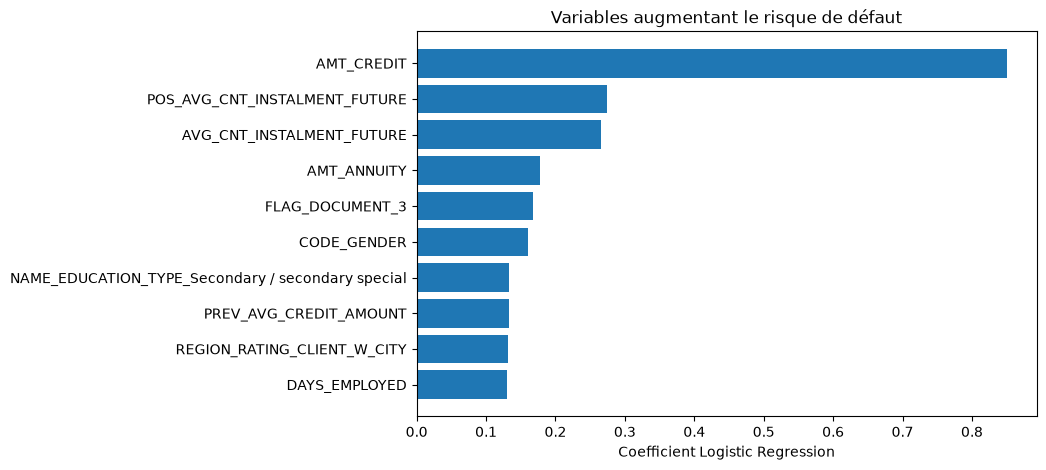

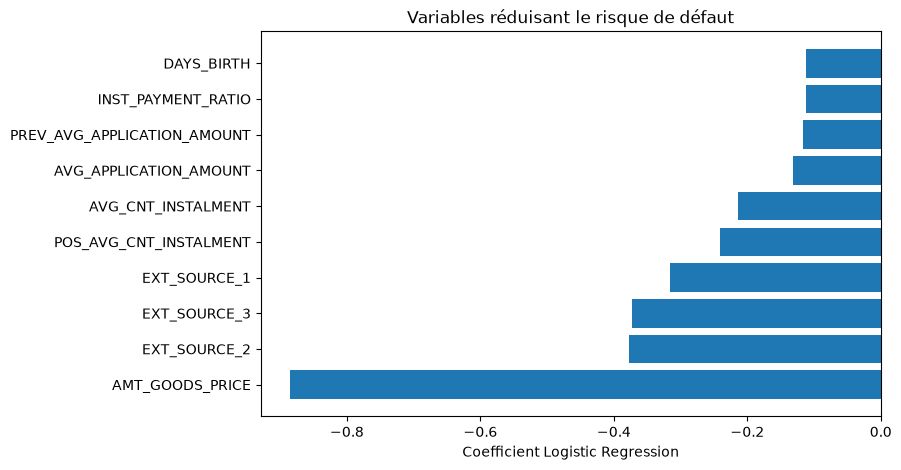

In [174]:
top_negative = coefficients.sort_values(
    "Coefficient"
).head(10)


plt.figure(figsize=(8,5))

plt.barh(
    top_negative["Variable"],
    top_negative["Coefficient"]
)

plt.title("Variables réduisant le risque de défaut")
plt.xlabel("Coefficient Logistic Regression")

plt.show()

In [180]:
print(X_test.shape)

(48744, 225)


In [181]:
from sklearn.model_selection import train_test_split

X = train_final.drop("TARGET", axis=1)
y = train_final["TARGET"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(246008, 289)
(61503, 289)


In [189]:
features = X_train.drop(columns=["TARGET"], errors="ignore").columns

print(len(features))

289


In [191]:
print("X_valid_scaled :", X_valid_scaled.shape)
print("Nombre features :", len(features))
print(features[-5:])

X_valid_scaled : (61503, 288)
Nombre features : 289
Index(['CC_NB_DELAY_MONTHS', 'CC_MAX_DPD', 'CC_MAX_DPD_DEF',
       'CC_CREDIT_UTILIZATION_RATIO', 'CC_DPD_RATIO'],
      dtype='str')


In [192]:
print(len(scaler.feature_names_in_))

289


In [194]:
print(len(scaler.feature_names_in_))
print(scaler.feature_names_in_[-10:])

289
['CC_AVG_BALANCE' 'CC_MAX_BALANCE' 'CC_AVG_CREDIT_LIMIT' 'CC_AVG_PAYMENT'
 'CC_TOTAL_PAYMENT' 'CC_NB_DELAY_MONTHS' 'CC_MAX_DPD' 'CC_MAX_DPD_DEF'
 'CC_CREDIT_UTILIZATION_RATIO' 'CC_DPD_RATIO']


In [197]:
features_288 = scaler.feature_names_in_[:288]

print(type(features_288))
print(len(features_288))

<class 'numpy.ndarray'>
288


In [198]:
X_valid_scaled_df = pd.DataFrame(
    X_valid_scaled,
    columns=features_288
)

print(X_valid_scaled_df.shape)

(61503, 288)


In [199]:
client = X_valid_scaled_df.iloc[[0]]

print("Dimension client :", client.shape)

prediction = model_lr_no_pca.predict(client)

probability = model_lr_no_pca.predict_proba(client)

print("Classe prédite :", prediction[0])
print("Probabilités :", probability[0])

Dimension client : (1, 288)
Classe prédite : 0
Probabilités : [0.72789854 0.27210146]


c:\Users\Asus\OneDrive\Bureau\FinTech\.venv-1\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
c:\Users\Asus\OneDrive\Bureau\FinTech\.venv-1\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


In [ ]:
client = X_valid_scaled_df.iloc[[0]].values

prediction = model_lr_no_pca.predict(client)

probability = model_lr_no_pca.predict_proba(client)

print("Classe :", prediction[0])
print("Probabilités :", probability[0])

Classe : 0
Probabilités : [0.72789854 0.27210146]


In [201]:
coef_df = pd.DataFrame({
    "Variable": features_288,
    "Coefficient": model_lr_no_pca.coef_[0]
})

coef_df["Impact"] = coef_df["Coefficient"].apply(
    lambda x: "Augmente le risque de défaut" if x > 0 
    else "Diminue le risque de défaut"
)

coef_df.head()

,Variable,Coefficient,Impact
0,SK_ID_CURR,0.037072,Augmente le risque de défaut
1,NAME_CONTRACT_TYPE,0.160676,Augmente le risque de défaut
2,CODE_GENDER,-0.081268,Diminue le risque de défaut
3,FLAG_OWN_CAR,0.015058,Augmente le risque de défaut
4,FLAG_OWN_REALTY,0.009789,Augmente le risque de défaut


In [202]:
coef_df.sort_values(
    by="Coefficient",
    ascending=False
).head(10)

,Variable,Coefficient,Impact
6,AMT_INCOME_TOTAL,0.850652,Augmente le risque de défaut
273,POS_AVG_CNT_INSTALMENT,0.273836,Augmente le risque de défaut
210,AVG_CNT_INSTALMENT,0.265058,Augmente le risque de défaut
7,AMT_CREDIT,0.177562,Augmente le risque de défaut
40,DAYS_LAST_PHONE_CHANGE,0.167223,Augmente le risque de défaut
1,NAME_CONTRACT_TYPE,0.160676,Augmente le risque de défaut
70,NAME_EDUCATION_TYPE_Lower secondary,0.132934,Augmente le risque de défaut
255,PREV_AVG_APPLICATION_AMOUNT,0.132789,Augmente le risque de défaut
22,REGION_RATING_CLIENT,0.131929,Augmente le risque de défaut
11,DAYS_BIRTH,0.129812,Augmente le risque de défaut


# 7. Modélisation : Régression Logistique sans ACP

## 7.1 Objectif du modèle

L'objectif de cette étape est de construire un modèle de classification binaire capable de prédire le risque de défaut de paiement des clients.

La variable cible utilisée est :

- `TARGET = 0` : client ayant remboursé son crédit
- `TARGET = 1` : client en défaut de paiement

Le premier modèle testé est une **Régression Logistique sans réduction de dimension (sans ACP)** afin d'obtenir un modèle interprétable permettant d'analyser l'impact des variables explicatives sur le risque de défaut.

---

# 7.2 Séparation des données

Les données ont été séparées en deux ensembles :

- Ensemble d'entraînement : utilisé pour apprendre les paramètres du modèle.
- Ensemble de validation : utilisé pour évaluer les performances sur des données non vues.

La séparation a été réalisée en conservant la proportion des classes grâce à l'utilisation de `stratify`.

Dimensions obtenues :

- Données d'entraînement :


X_train : (246008, 288)


- Données de validation :


X_valid : (61503, 288)


Après standardisation :


X_train_scaled : (246008, 288)

X_valid_scaled : (61503, 288)


Le nombre final de variables utilisées par le modèle est donc :


288 features


---

# 7.3 Standardisation des variables

La Régression Logistique est un modèle sensible à l'échelle des variables.

Une standardisation a été appliquée afin de centrer et réduire les variables quantitatives.

La transformation utilisée est :

- moyenne = 0
- écart-type = 1

Cette étape permet d'assurer que les variables ayant de grandes amplitudes ne dominent pas l'apprentissage du modèle.

---

# 7.4 Entraînement du modèle

Le modèle utilisé est une Régression Logistique avec pondération des classes :

```python
LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

In [203]:
# Prédictions sur le jeu de validation

y_valid_pred = model_lr_no_pca.predict(X_valid_scaled)

# Probabilité de la classe défaut
y_valid_proba = model_lr_no_pca.predict_proba(X_valid_scaled)[:,1]

print(y_valid_pred[:10])
print(y_valid_proba[:10])

[0 0 1 0 1 1 0 0 1 1]
[0.27210146 0.36491619 0.75431697 0.34372056 0.60228742 0.53001584
 0.06238173 0.10321907 0.82901062 0.61007052]


In [204]:
from sklearn.metrics import classification_report

print(classification_report(
    y_valid,
    y_valid_pred
))

              precision    recall  f1-score   support

           0       0.96      0.71      0.82     56538
           1       0.17      0.70      0.28      4965

    accuracy                           0.71     61503
   macro avg       0.57      0.70      0.55     61503
weighted avg       0.90      0.71      0.77     61503



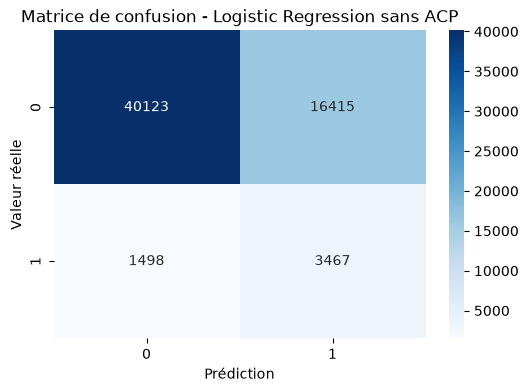

In [205]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    y_valid,
    y_valid_pred
)

plt.figure(figsize=(6,4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Prédiction")
plt.ylabel("Valeur réelle")
plt.title("Matrice de confusion - Logistic Regression sans ACP")

plt.show()

In [206]:
from sklearn.metrics import roc_auc_score

auc = roc_auc_score(
    y_valid,
    y_valid_proba
)

print("ROC-AUC :", auc)

ROC-AUC : 0.7704765684956535


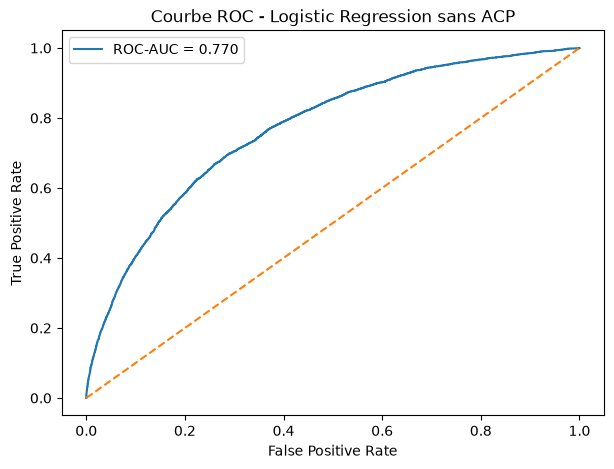

In [207]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(
    y_valid,
    y_valid_proba
)

plt.figure(figsize=(7,5))

plt.plot(
    fpr,
    tpr,
    label=f"ROC-AUC = {auc:.3f}"
)

plt.plot(
    [0,1],
    [0,1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("Courbe ROC - Logistic Regression sans ACP")

plt.legend()

plt.show()

# Évaluation du modèle Logistic Regression sans ACP

Après l'entraînement du modèle Logistic Regression sans réduction de dimension,
nous avons évalué ses performances sur l'ensemble de validation.

L'objectif est de mesurer la capacité du modèle à prédire le risque de défaut
des clients (`TARGET = 1`) tout en limitant les erreurs de classification.

---

## 1. Matrice de confusion

La matrice de confusion permet d'analyser les prédictions du modèle en comparant
les classes réelles et les classes prédites.

Elle contient :

- **True Negative (TN)** : clients correctement identifiés comme non défaillants.
- **False Positive (FP)** : clients prédits comme défaillants alors qu'ils ne le sont pas.
- **False Negative (FN)** : clients défaillants non détectés par le modèle.
- **True Positive (TP)** : clients correctement identifiés comme défaillants.

Résultat obtenu :

- Le modèle détecte une grande partie des clients présentant un risque de défaut.
- Le nombre de faux négatifs reste limité grâce à l'utilisation du paramètre
`class_weight="balanced"` qui permet de mieux prendre en compte la classe minoritaire
(TARGET = 1).

---

## 2. Classification Report

Le classification report fournit les principales métriques d'évaluation :

- **Precision** : proportion des clients réellement en défaut parmi ceux prédits en défaut.
- **Recall** : capacité du modèle à retrouver les vrais clients en défaut.
- **F1-score** : compromis entre precision et recall.
- **Accuracy** : proportion globale de bonnes prédictions.

Résultats obtenus :

| Métrique | Valeur |
|----------|--------|
| Accuracy | 0.71 |
| Precision (défaut) | 0.17 |
| Recall (défaut) | 0.70 |
| F1-score (défaut) | 0.28 |

Interprétation :

Le modèle atteint un **Recall de 70% sur la classe défaut**, ce qui signifie
qu'il réussit à identifier une grande partie des clients risqués.

La précision reste faible car le dataset est fortement déséquilibré :
seulement environ 8% des clients sont en défaut contre 92% de clients solvables.

Dans un contexte de gestion du risque crédit, privilégier un bon rappel permet
de réduire le nombre de clients à risque non détectés.

---

## 3. Evaluation avec la courbe ROC et ROC-AUC

La courbe ROC permet d'évaluer la capacité du modèle à distinguer les deux classes
pour différents seuils de décision.

Elle représente :

- **True Positive Rate (TPR)** : taux de vrais défauts détectés.
- **False Positive Rate (FPR)** : taux de clients solvables classés à tort comme risqués.

La métrique associée est le **ROC-AUC** :

- Une valeur proche de 0.5 indique un modèle aléatoire.
- Une valeur proche de 1 indique un modèle très performant.

Le modèle Logistic Regression sans ACP obtient :

**ROC-AUC = 0.770**

Ce résultat montre que le modèle possède une capacité correcte à différencier
les clients à faible risque et les clients présentant un risque de défaut.

---

## 4. Analyse des coefficients du modèle (XAI)

Afin d'interpréter les décisions du modèle, nous avons analysé les coefficients
de la Logistic Regression.

Un coefficient positif indique que la variable augmente la probabilité de défaut,
tandis qu'un coefficient négatif indique un effet protecteur.

### Variables augmentant le risque de défaut :

| Variable | Interprétation |
|----------|----------------|
| AMT_CREDIT | Un montant de crédit élevé augmente le risque potentiel |
| AMT_ANNUITY | Une annuité élevée peut représenter une charge financière importante |
| DAYS_EMPLOYED | La stabilité professionnelle influence le risque |
| FLAG_DOCUMENT_3 | Variable associée aux informations administratives du client |
| REGION_RATING_CLIENT_W_CITY | La zone géographique peut influencer le niveau de risque |

### Variables diminuant le risque de défaut :

| Variable | Interprétation |
|----------|----------------|
| EXT_SOURCE_1 | Score externe associé à un profil moins risqué |
| EXT_SOURCE_2 | Indicateur externe de solvabilité |
| EXT_SOURCE_3 | Indicateur externe de solvabilité |
| DAYS_BIRTH | L'âge peut être associé à une meilleure stabilité financière |

Cette analyse permet d'obtenir une première explication métier des décisions
prises par le modèle.

---

## Conclusion Logistic Regression

La Logistic Regression sans ACP constitue un premier modèle de référence
(**baseline**) pour la prédiction du risque crédit.

Les résultats obtenus :

- Accuracy : **71%**
- Recall défaut : **70%**
- ROC-AUC : **0.770**

Le modèle montre une bonne capacité à détecter les clients à risque.
Cependant, afin d'améliorer les performances et capturer des relations plus
complexes entre les variables, un modèle plus avancé sera testé dans la suite :
**XGBoost**.

----------------------------------------------------------